# S2-03 · Daily ticket history

Counts tickets per department per day in SAST, fills empty days with 0, and charts all four departments.

Input: a CSV export of the `tickets` table saved as `ml/data/tickets.csv` (Supabase Table Editor → Export). Needs at least `department` and `created_at`.

Until S2-09 (`dashboard_metrics()`) lands, this notebook reads tickets directly. Switch over once Mihlali confirms a daily series is available.

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = next(p for p in [Path('../data'), Path('ml/data'), Path('data')] if (p / 'tickets.csv').exists())
print('Using data folder:', DATA.resolve())

tickets = pd.read_csv(DATA / 'tickets.csv')
tickets['is_historical'] = tickets['is_historical'].astype(str).str.lower().isin(['t', 'true'])
tickets['created_at'] = pd.to_datetime(tickets['created_at'], format='ISO8601', utc=True).dt.tz_convert('Africa/Johannesburg')
tickets['day'] = tickets['created_at'].dt.tz_localize(None).dt.normalize()

print(tickets.shape)
print(tickets['is_historical'].value_counts())

Using data folder: C:\Users\CAPACITI-JHB\Projects\relay\ml\data
(518, 6)
is_historical
True     500
False     18
Name: count, dtype: int64


In [77]:
end = pd.Timestamp.now(tz='Africa/Johannesburg').tz_localize(None).normalize()

periods = {
    'historical': (pd.Timestamp('2025-10-19'), pd.Timestamp('2025-10-30')),
    'live': (pd.Timestamp('2026-10-21'), end),
}

frames = []
for name, (p_start, p_end) in periods.items():
    is_hist = name == 'historical'
    subset = tickets[(tickets['is_historical'] == is_hist) & (tickets['day'] >= p_start) & (tickets['day'] <= p_end)]
    days = pd.date_range(p_start, p_end, freq='D')
    c = (
        subset.groupby(['day', 'department'])
        .size()
        .unstack('department')
        .reindex(days, fill_value=0)
        .fillna(0)
        .astype(int)
    )
    c.index.name = 'day'
    c.insert(0, 'period', name)
    frames.append(c)

daily = pd.concat(frames)
daily.to_csv(DATA / 'daily_counts.csv')
counts = daily.drop(columns='period')
daily.tail(10)

department,period,Finance,HR,IT,Operations
day,,,,,
2026-10-25,live,0,0,0,0
2026-10-26,live,0,0,0,0
2026-10-27,live,0,0,0,0
2026-10-28,live,0,0,1,0
2026-10-29,live,4,2,1,1
2026-10-30,live,1,0,1,1
2026-10-31,live,0,0,0,0
2026-11-01,live,0,0,0,0
2026-11-02,live,0,0,0,0


In [78]:
# Make sure is_historical is true/false, not text ('t'/'f')
tickets['is_historical'] = tickets['is_historical'].astype(str).str.lower().isin(['t', 'true'])

# Checks: totals match the tickets in each period, and no days are missing inside a period
in_periods = pd.concat([
    tickets[tickets['is_historical'] & tickets['day'].between(*periods['historical'])],
    tickets[~tickets['is_historical'] & tickets['day'].between(*periods['live'])],
])

assert counts.values.sum() == len(in_periods), 'Daily totals do not match the ticket count'
expected_days = sum(len(pd.date_range(s, e)) for s, e in periods.values())
assert len(daily) == expected_days, 'Missing days inside a period'

print('Tickets counted:', len(in_periods), 'of', len(tickets))
for name, (s, e) in periods.items():
    print(name, s.date(), 'to', e.date(), len(pd.date_range(s, e)), 'days')

Tickets counted: 518 of 518
historical 2025-10-19 to 2025-10-30 12 days
live 2026-10-21 to 2026-11-03 14 days


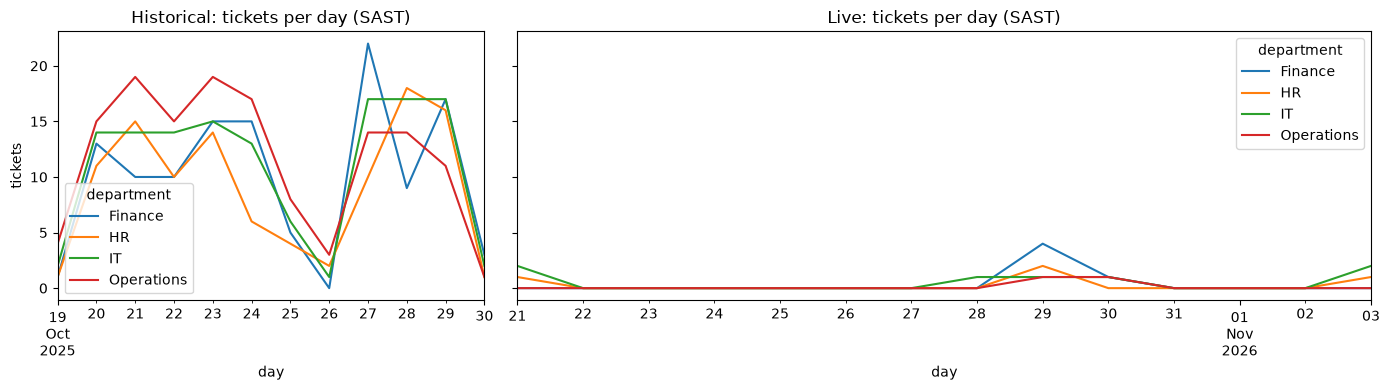

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, gridspec_kw={'width_ratios': [1, 2]})
for ax, name in zip(axes, periods):
    daily.loc[daily['period'] == name].drop(columns='period').plot(ax=ax, title=f'{name.capitalize()}: tickets per day (SAST)')
    ax.set_ylabel('tickets')
plt.tight_layout()
plt.savefig(DATA / 'daily_history.png', dpi=150)
plt.show()

In [80]:
# Quick look at the weekday pattern, to check the chart before the forecast is built on it.
weekday_avg = counts.groupby(counts.index.dayofweek).mean().round(1)
weekday_avg.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_avg

department,Finance,HR,IT,Operations
Mon,8.8,5.2,7.8,7.2
Tue,4.8,8.5,8.2,8.2
Wed,6.8,6.8,8.5,6.5
Thu,5.5,4.2,4.5,5.2
Fri,5.3,2.0,4.7,6.0
Sat,1.7,1.3,2.0,2.7
Sun,0.2,0.8,0.8,1.8


In [81]:
print(tickets.columns.tolist())
tickets.head()

['id', 'department', 'created_at', 'is_historical', 'status', 'day']


,id,department,created_at,is_historical,status,day
0,1,IT,2026-10-21 15:35:25.056690+02:00,False,answered,2026-10-21
1,2,HR,2026-10-21 15:35:25.056690+02:00,False,answered,2026-10-21
2,3,IT,2026-10-21 15:35:25.056690+02:00,False,answered,2026-10-21
3,4,IT,2026-10-28 16:00:35.582268+02:00,False,answered,2026-10-28
4,5,Finance,2026-10-29 08:39:32.312103+02:00,False,answered,2026-10-29


In [82]:
with open(DATA / 'tickets.csv', encoding='utf-8-sig') as f:
    print(repr(f.readline()))

'id,department,created_at,is_historical,status\n'


In [83]:
tickets = pd.read_csv(DATA / 'tickets.csv')

In [84]:
with open(DATA / 'tickets.csv', encoding='utf-8-sig') as f:
    lines = f.readlines()
print('lines:', len(lines))
for line in lines[:3]:
    print(repr(line))

lines: 519
'id,department,created_at,is_historical,status\n'
'1,IT,2026-10-21 13:35:25.05669+00,f,answered\n'
'2,HR,2026-10-21 13:35:25.05669+00,f,answered\n'


In [85]:
with open(DATA / 'tickets.csv', encoding='utf-8-sig') as f:
    lines = [l.strip().strip('"') for l in f.read().replace('\r', '').split('\n')]
lines = [l for l in lines if l and l != 'csv']

with open(DATA / 'tickets.csv', 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines) + '\n')
print('lines after cleaning:', len(lines))

lines after cleaning: 519


In [86]:
print(tickets['is_historical'].dtype, tickets['is_historical'].unique())

str <ArrowStringArray>
['f', 't']
Length: 2, dtype: str


In [87]:
from pathlib import Path
print('Working folder:', Path.cwd())
print([str(p) for p in Path.cwd().parent.parent.rglob('tickets.csv')])

Working folder: c:\Users\CAPACITI-JHB\Projects\relay\ml\notebooks
['c:\\Users\\CAPACITI-JHB\\Projects\\relay\\ml\\data\\tickets.csv']
